# 內容過濾推薦與首次配置建議

**目的**：期望價值排序決定了「接觸誰」（951 人）和「每月扣多少」，這裡決定「推薦什麼」：依客戶的消費輪廓挑出一檔**核心**和一檔**衛星**商品，並依 KYC 等級分配金額（計畫書 4.5）。

| 步驟 | 內容 |
| --- | --- |
| 1 | 建立商品權重表（9 檔商品 × 10 個消費類別） |
| 2 | 建立客戶向量（10 個消費類別的刷卡金額占比），計算 cosine 相似度 |
| 3 | KYC 過濾後，在核心、衛星候選中各自挑分數最高的一檔；同分時列出候選讓客戶擇一 |
| 4 | 依 KYC 等級分配核心與衛星的金額 |
| 5 | 產生推薦理由 |
| 6 | 評估：合規率、配置合理性、覆蓋率、方向檢查 |
| 7 | 輸出推薦結果 |

> 這是依業務邏輯建立的**內容過濾規則**，不是機器學習模型：資料中沒有商品層級的購買紀錄，所以**無法評估推薦準不準**，只能評估合規率、覆蓋率與配置是否合理。
>
> 本專案使用模擬資料，以下所有結果都是**模擬資料中的規律**，在真實情境下是否成立需要驗證（見計畫書 1.5）。

## 0. 環境設定與讀取資料

In [ ]:
import os, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 中文字型:Colab(Linux)沒有內建中文字型,找不到時自動安裝 Noto Sans CJK
CJK_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not any(f.name.startswith(("Microsoft JhengHei", "PingFang", "Heiti", "Noto Sans CJK")) for f in fm.fontManager.ttflist):
    if not os.path.exists(CJK_FONT):
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
    fm.fontManager.addfont(CJK_FONT)

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

MAIN = "#2a78d6"     # P09(分散型核心)
REF = "#52514e"      # 其他商品
MUTED = "#a8a7a2"    # 同分、次要資訊
pd.set_option("display.max_columns", None)

# 參數(計畫書 4.5、附錄 A),集中在這裡定義
CATS = ["3C科技", "母嬰用品", "旅遊", "加油/交通", "居家生活", "外送平台", "餐飲", "精品/百貨", "超市/量販", "其他"]
CORE = ["P01", "P02", "P03", "P08", "P09"]
SATELLITE = ["P04", "P07", "P05", "P06"]
KYC_MAX_RISK = {"保守型": 2, "穩健型": 3, "積極型": 5}
SAT_RATIO = {"保守型": 0.0, "穩健型": 0.2, "積極型": 0.3}
MIN_PER_PRODUCT = 1_000          # 每檔最低扣款
SAT_MIN_SIP = {"穩健型": 5_000, "積極型": 4_000}   # 月扣款達到這個金額,衛星才會 ≥ 1,000

In [ ]:
def path(name, folder):
    """Colab 直接上傳時檔案在根目錄;下載整個 repo 執行時在資料夾裡"""
    return name if os.path.exists(name) else os.path.join(folder, name)

contact = pd.read_csv(path("contact_list.csv", "outputs"))             # 期望價值排序第 6 節的輸出
profile = pd.read_csv(path("client_profile_cleaned.csv", "data_cleaned"))
card_transactions = pd.read_csv(path("card_transactions_cleaned.csv", "data_cleaned"), parse_dates=["transaction_month"])
catalog = pd.read_csv(path("product_catalog_cleaned.csv", "data_cleaned")).set_index("product_id")

df = contact.loc[contact["in_top20"], ["customer_id", "sip"]].reset_index(drop=True)
df["sip"] = df["sip"].astype(int)
df["kyc"] = df["customer_id"].map(profile.set_index("customer_id")["kyc_risk_rating"])

assert len(df) == 951 and df["customer_id"].is_unique and df["kyc"].notna().all()
assert set(catalog.index) == set(CORE + SATELLITE)
assert card_transactions["transaction_month"].nunique() == 6
print("接觸名單:", len(df), "人")
print(df["kyc"].value_counts().reindex(KYC_MAX_RISK).to_string())
catalog

接觸名單: 951 人
kyc
保守型    270
穩健型    350
積極型    331


,product_name,asset_class,category,risk_rating
product_id,,,,
P01,安穩債券精選基金,債券型,美債,1
P02,全球平衡配置基金,平衡型,平衡型,2
P03,高股息優選ETF,股票型,高股息,2
P04,低碳永續主題基金,股票型,低碳永續,3
P05,科技創新旗艦ETF,股票型,科技,4
P06,新興市場增長基金,股票型,新興市場,4
P07,全球旅遊消費主題基金,股票型,消費主題,3
P08,家庭防禦均衡基金,股票型,價值型,2
P09,全球市值型指數ETF,股票型,全球市值型,3


## 1. 商品權重表

- 權重代表**興趣與主題的關聯**，**不代表風險承受度**；風險一律由 KYC 過濾決定。
- 只用三個等級：**1.0** 直接對應、**0.5** 間接相關、**0** 無關（空白）。
- **cosine 只看方向、不看大小**：1.0 和 0.5 只有在**同一檔商品內**比較才有意義；不同商品之間的勝負，取決於權重的「形狀」（對應哪幾個類別、多集中）。
- App 標籤只有 5 種，對應 P01–P05；**P06–P09 沒有對應的標籤，權重只能依業務邏輯設定**。點擊資料是模擬的，所以權重只能說「參考了模擬資料中的瀏覽行為」，不能說「經過驗證」。

| 消費類別 | 商品 | 權重 | 依據 | 理由 |
| --- | --- | --- | --- | --- |
| 全部 | P09 全球市值 | 0.5 | 直覺 | 沒有特定主題的分散型商品，適合消費沒有明顯偏好的客戶 |
| 3C科技 | P05 科技 | 1.0 | 兩者 | Q7：3C 客戶 95% 最常點擊科技；3C 與科技同性質 |
| 母嬰用品 | P01 美債 | 0.5 | 兩者 | Q7：母嬰客戶 56% 最常點擊美債；適合需要穩定支出的家庭階段 |
| 母嬰用品 | P02 平衡 | 0.5 | 資料 | Q7：母嬰客戶 35% 最常點擊平衡型 |
| 旅遊 | P02 平衡 | 0.5 | 資料 | Q7：旅遊客戶 31% 最常點擊平衡型 |
| 旅遊 | P03 高股息 | 0.5 | 資料 | Q7：旅遊客戶 52% 最常點擊高股息 |
| 旅遊 | P07 旅遊消費 | 1.0 | 直覺 | 旅遊與旅遊消費主題同性質 |
| 加油/交通 | P04 低碳永續 | 0.5 | 兩者 | Q7：低碳永續約 31%，略高於平均；交通與能源轉型相關 |
| 居家生活 | P04 低碳永續 | 0.5 | 資料 | Q7：低碳永續約 31%，略高於平均 |
| 居家生活 | P08 家庭防禦 | 0.5 | 直覺 | 與民生需求相關 |
| 外送平台 | P04 低碳永續 | 0.5 | 兩者 | Q7：低碳永續約 27%；外送使用的交通工具與低碳相關 |
| 外送平台 | P07 旅遊消費 | 0.5 | 直覺 | 屬於消費支出，與景氣和消費意願相關 |
| 餐飲 | P07 旅遊消費 | 0.5 | 直覺 | 屬於消費支出 |
| 精品/百貨 | P07 旅遊消費 | 0.5 | 直覺 | 屬於消費支出 |
| 精品/百貨 | P06 新興市場 | 0.5 | 直覺 | 關聯較弱；P06 沒有直接對應的消費類別，設定這一格讓它有機會被推薦 |
| 超市/量販 | P08 家庭防禦 | 0.5 | 直覺 | 與民生需求相關 |

**母嬰的處理**：資料（美債 56%、平衡型 35%）優先，直覺的 P08 不對應母嬰。P01 只對應母嬰、P02 對應母嬰＋旅遊，靠「形狀」讓消費集中在母嬰的客戶選 P01。

In [ ]:
WEIGHTS = {   # 只列非零權重,其餘為 0
    "P01": {"母嬰用品": 0.5},
    "P02": {"母嬰用品": 0.5, "旅遊": 0.5},
    "P03": {"旅遊": 0.5},
    "P08": {"居家生活": 0.5, "超市/量販": 0.5},
    "P09": {c: 0.5 for c in CATS},
    "P04": {"加油/交通": 0.5, "居家生活": 0.5, "外送平台": 0.5},
    "P07": {"旅遊": 1.0, "外送平台": 0.5, "餐飲": 0.5, "精品/百貨": 0.5},
    "P05": {"3C科技": 1.0},
    "P06": {"精品/百貨": 0.5},
}
W = pd.DataFrame(WEIGHTS).reindex(index=CATS, columns=CORE + SATELLITE).fillna(0)

assert (W.gt(0).sum() >= 1).all()            # 每檔商品至少一個非零權重,否則永遠不會被推薦
assert W.isin([0, 0.5, 1.0]).all().all()
W.style.format(lambda v: f"{v:.1f}" if v else "")

,P01,P02,P03,P08,P09,P04,P07,P05,P06
3C科技,,,,,0.5,,,1.0,
母嬰用品,0.5,0.5,,,0.5,,,,
旅遊,,0.5,0.5,,0.5,,1.0,,
加油/交通,,,,,0.5,0.5,,,
居家生活,,,,0.5,0.5,0.5,,,
外送平台,,,,,0.5,0.5,0.5,,
餐飲,,,,,0.5,,0.5,,
精品/百貨,,,,,0.5,,0.5,,0.5
超市/量販,,,,0.5,0.5,,,,
其他,,,,,0.5,,,,


## 2. 客戶向量與相似度

- **客戶向量**：每位客戶近 6 個月（2026/03–2026/08）在 10 個消費類別的刷卡金額占比，每列加總 = 1。App 點擊不放進客戶向量（只用來決定權重）。
- **相似度**：cosine similarity = 兩個向量各自除以長度後的內積。客戶向量和權重都沒有負值，所以分數介於 0～1。

In [ ]:
spend = card_transactions.pivot_table(index="customer_id", columns="mcc_category",
                                      values="transaction_amount", aggfunc="sum", fill_value=0)
assert set(spend.columns) == set(CATS)
X = spend.reindex(index=df["customer_id"], columns=CATS)
X = X.div(X.sum(axis=1), axis=0)

assert X.notna().all().all() and np.allclose(X.sum(axis=1), 1)

def unit(a, axis):
    """把向量除以自己的長度(axis=1:每一列;axis=0:每一欄)"""
    return a / np.linalg.norm(a, axis=axis, keepdims=True)

S = pd.DataFrame(unit(X.values, 1) @ unit(W.values, 0), index=X.index, columns=W.columns)
assert ((S >= 0) & (S <= 1 + 1e-9)).all().all()

df["top_cat"] = X.idxmax(axis=1).values          # 主要消費類別(只用於解讀與方向檢查)
df["top_share"] = X.max(axis=1).values
print("主要消費類別的占比:中位數", f"{df['top_share'].median():.1%}",
      f",超過 1/√10 ≈ 31.6% 的比例 {(df['top_share'] > 1 / np.sqrt(10)).mean():.1%}")
S.head().round(3)

主要消費類別的占比:中位數 31.7% ,超過 1/√10 ≈ 31.6% 的比例 50.2%


,P01,P02,P03,P08,P09,P04,P07,P05,P06
customer_id,,,,,,,,,
C108134,0.471,0.696,0.513,0.138,0.753,0.499,0.607,0.049,0.046
C103236,0.598,0.605,0.258,0.226,0.850,0.377,0.510,0.227,0.488
C104381,0.700,0.894,0.563,0.356,0.647,0.060,0.467,0.059,0.049
C100492,0.214,0.228,0.109,0.262,0.831,0.525,0.520,0.534,0.477
C101685,0.000,0.407,0.576,0.112,0.727,0.365,0.752,0.000,0.384


## 3. KYC 過濾與挑選商品

1. **合規過濾**：只保留風險等級 ≤ KYC 上限的商品（保守型 1–2、穩健型 1–3、積極型 1–5）。
2. 在**核心候選**、**衛星候選**中**各自**挑分數最高的一檔。保守型沒有衛星。
3. **同分規則**：同一組候選中，最高分有多檔（用 `np.isclose` 判斷，包括全部 0 分）時，**不替客戶判斷**，把同分的商品全部列出讓客戶擇一，並標記「同分，由客戶選擇」。全部 0 分時，列出的就是 KYC 允許的全部候選。

In [ ]:
def pick(scores, candidates):
    """回傳 (推薦商品清單, 是否同分):最高分只有一檔時清單只有一檔"""
    sc = scores[candidates]
    best = [p for p in candidates if np.isclose(sc[p], sc.max())]
    return best, len(best) > 1

def allowed(group, kyc):
    return [p for p in group if catalog.loc[p, "risk_rating"] <= KYC_MAX_RISK[kyc]]

core_pick = [pick(S.loc[c], allowed(CORE, k)) for c, k in zip(df["customer_id"], df["kyc"])]
sat_pick = [pick(S.loc[c], allowed(SATELLITE, k)) if k != "保守型" else ([], False)
            for c, k in zip(df["customer_id"], df["kyc"])]
df["core_list"], df["core_tie"] = zip(*core_pick)
df["sat_list"], df["satellite_tie"] = zip(*sat_pick)
df["core_all_zero"] = [np.isclose(S.loc[c, allowed(CORE, k)].max(), 0) for c, k in zip(df["customer_id"], df["kyc"])]

def label(products, tie):
    return "／".join(products) + ("（擇一）" if tie else "")

df["core_label"] = [label(p, t) for p, t in zip(df["core_list"], df["core_tie"])]
df["sat_label"] = [label(p, t) for p, t in zip(df["sat_list"], df["satellite_tie"])]

print("核心同分:", df["core_tie"].sum(), "人(其中全部 0 分", df["core_all_zero"].sum(), "人)")
print("衛星同分:", df["satellite_tie"].sum(), "人")
print(df.loc[df["core_tie"], ["customer_id", "kyc", "top_cat", "core_label"]].to_string(index=False))

核心同分: 1 人(其中全部 0 分 1 人)
衛星同分: 0 人
customer_id kyc top_cat          core_label
    C104853 保守型      其他 P01／P02／P03／P08（擇一）


In [ ]:
def distribution(col, kyc):
    return df.loc[df["kyc"] == kyc, col].value_counts()

rows = {f"{k} 核心": distribution("core_label", k) for k in KYC_MAX_RISK}
rows.update({f"{k} 衛星(套用金額規則前)": distribution("sat_label", k) for k in ["穩健型", "積極型"]})
pick_table = pd.DataFrame(rows).T.fillna(0).astype(int)
pick_table = pick_table[[c for c in CORE + SATELLITE if c in pick_table] + [c for c in pick_table if "擇一" in c]]
pick_table

,P01,P02,P03,P08,P09,P04,P07,P05,P06,P01／P02／P03／P08（擇一）
保守型 核心,89,41,37,102,0,0,0,0,0,1
穩健型 核心,48,13,13,21,255,0,0,0,0,0
積極型 核心,35,3,8,14,271,0,0,0,0,0
穩健型 衛星(套用金額規則前),0,0,0,0,0,196,154,0,0,0
積極型 衛星(套用金額規則前),0,0,0,0,0,118,81,100,32,0


## 4. 分配金額

| KYC | 核心：衛星 |
| --- | --- |
| 保守型 | 100%：0% |
| 穩健型 | 80%：20% |
| 積極型 | 70%：30% |

- 月扣款總額沿用期望價值排序的建議月扣款（千元整數）。
- **嚴格遵守比例、不取整**：衛星 = 月扣款 × 衛星比例，核心 = 月扣款 − 衛星。衛星會是 200 或 300 的倍數，所以假設**扣款金額以百元為單位**（附錄 A）。
- **衛星金額不足 1,000 元**（每檔最低扣款）：只配置核心，並說明「月扣款增加到 X 元以上，可以加入衛星配置」（穩健型 5,000、積極型 4,000）。這是唯一不符合比例的例外。

In [ ]:
sat_raw = (df["sip"] * df["kyc"].map(SAT_RATIO)).round().astype(int)
df["satellite_shortfall"] = (sat_raw > 0) & (sat_raw < MIN_PER_PRODUCT)
df["satellite_amount"] = sat_raw.where(~df["satellite_shortfall"], 0)
df["core_amount"] = df["sip"] - df["satellite_amount"]
df["sat_list"] = [[] if s else p for p, s in zip(df["sat_list"], df["satellite_shortfall"])]
df["sat_label"] = [label(p, t) if p else "" for p, t in zip(df["sat_list"], df["satellite_tie"])]
df["satellite_tie"] = df["satellite_tie"] & ~df["satellite_shortfall"]

assert (df["core_amount"] + df["satellite_amount"] == df["sip"]).all()
assert (df["core_amount"] >= MIN_PER_PRODUCT).all()
assert ((df["satellite_amount"] == 0) | (df["satellite_amount"] >= MIN_PER_PRODUCT)).all()
assert ((df["core_amount"] % 100 == 0) & (df["satellite_amount"] % 100 == 0)).all()   # 百元為單位
assert (df.loc[df["kyc"] == "保守型", "satellite_amount"] == 0).all()
has_sat = df["satellite_amount"] > 0
ratio = df.loc[has_sat, "satellite_amount"] / df.loc[has_sat, "sip"]
assert np.allclose(ratio, df.loc[has_sat, "kyc"].map(SAT_RATIO))       # 有衛星的人都符合比例

print("衛星金額不足、只配置核心:", df["satellite_shortfall"].sum(), "人",
      df.loc[df["satellite_shortfall"], "kyc"].value_counts().to_dict())
not_thousand = has_sat & (df["satellite_amount"] % 1000 != 0)
print("有衛星且金額不是千元整數:", not_thousand.sum(), "人(需要「以百元為單位」的假設)")
df.loc[has_sat, ["kyc", "sip", "core_amount", "satellite_amount"]].drop_duplicates(["kyc", "sip"]).sort_values(["kyc", "sip"]).head(8)

衛星金額不足、只配置核心: 8 人 {'穩健型': 6, '積極型': 2}
有衛星且金額不是千元整數: 315 人(需要「以百元為單位」的假設)


,kyc,sip,core_amount,satellite_amount
563,積極型,4000,2800,1200
571,積極型,5000,3500,1500
176,積極型,6000,4200,1800
153,積極型,7000,4900,2100
48,積極型,8000,5600,2400
24,積極型,9000,6300,2700
1,積極型,10000,7000,3000
236,穩健型,5000,4000,1000


**我的解讀**：

保守型的核心推薦中，哪一檔最多:

P08（102 人，37.8%）最多。可能的原因是：

保守型不能買 P09，主要消費類別沒有核心商品可以對應的客戶，

會改由次要消費決定；P08 對應的居家和超市是大部分人都會花費的民生支出，

所以 P08 比較容易拿到分數。（第六節做驗證）

穩健型的核心推薦中，P09 占多少？

255(72.9%)

積極型的核心推薦中，P09 占多少？

271(81.9%)

原因:

1.P09在所有消費類別都有對應，消費類別越分散的客戶跟他越相似。

2.母嬰、旅遊、居家以及超市量販以外類別，除了P09外沒有其他核心產品可以選擇


為什麼適合:
核心的目的是分散、長期持有，市值型ETF很適合放在這邊

代價:
核心推薦的個人化程度低，大部分人核心都用同檔產品。
個人化主要靠衛星配置來呈現

同分與全部 0 分的有幾人？
1人(保守型)，核心推薦全部0分，
列出P01／P02／P03／P08讓客戶選擇一個

衛星金額不足的有幾人，他們會收到什麼建議？

8人(穩健型 6人、積極型 2人)，月扣款先全部配置到核心，

他們會得到的建議:

穩健型:月扣款達到 5,000 元以上，可以加入衛星配置

積極型:月扣款達到 4,000 元以上，可以加入衛星配置


## 5. 推薦理由

| 模板 | 使用條件 | 文字 |
| --- | --- | --- |
| 主題型 | 推薦的商品不是 P09，且沒有同分 | 「你在{類別}的消費占比為 {X}%，推薦{商品名稱}」。{類別} 取「客戶占比 × 該商品權重」最大的類別，也就是對分數貢獻最大的類別 |
| 分散型 | 推薦的商品是 P09 | 「你的消費分布在多個類別，沒有特別集中，推薦分散投資的{商品名稱}」 |
| 只有核心配置 | 保守型；或衛星金額不足 | 保守型：「依你的風險屬性，建議全部配置在核心資產」；衛星不足：「月扣款增加到 {X} 元以上，可以加入衛星配置」 |
| 資料不足 | 同分（包括全部 0 分） | 「目前沒有足夠的消費資料判斷你的偏好，以下商品請擇一」 |

**文案不得暗示報酬**，例如不寫「可創造超額報酬」「穩健獲利」。

In [ ]:
def theme_reason(cid, products, tie):
    if tie:
        return "目前沒有足夠的消費資料判斷你的偏好，以下商品請擇一"
    p = products[0]
    name = catalog.loc[p, "product_name"]
    if p == "P09":
        return f"你的消費分布在多個類別，沒有特別集中，推薦分散投資的{name}"
    contrib = X.loc[cid] * W[p]
    cat = contrib.idxmax()
    return f"你在{cat}的消費占比為 {X.loc[cid, cat]:.0%}，推薦{name}"

def satellite_reason(row):
    if row["kyc"] == "保守型":
        return "依你的風險屬性，建議全部配置在核心資產"
    if row["satellite_shortfall"]:
        return f"月扣款增加到 {SAT_MIN_SIP[row['kyc']]:,} 元以上，可以加入衛星配置"
    return theme_reason(row["customer_id"], row["sat_list"], row["satellite_tie"])

df["core_reason"] = [theme_reason(c, p, t) for c, p, t in zip(df["customer_id"], df["core_list"], df["core_tie"])]
df["satellite_reason"] = df.apply(satellite_reason, axis=1)

BANNED = ["報酬", "獲利", "賺"]
assert not df[["core_reason", "satellite_reason"]].apply(lambda s: s.str.contains("|".join(BANNED))).any().any()

# 每種 KYC 各舉一例
examples = df.groupby("kyc", sort=False).head(1)
for _, r in examples.iterrows():
    print(f"[{r['kyc']}] 月扣款 {r['sip']:,} 元")
    print(f"  核心 {r['core_label']} {r['core_amount']:,} 元:{r['core_reason']}")
    sat = f"{r['sat_label']} {r['satellite_amount']:,} 元:" if r["satellite_amount"] else ""
    print(f"  衛星 {sat}{r['satellite_reason']}")

[保守型] 月扣款 10,000 元
  核心 P02 10,000 元:你在旅遊的消費占比為 22%，推薦全球平衡配置基金
  衛星 依你的風險屬性，建議全部配置在核心資產
[積極型] 月扣款 10,000 元
  核心 P09 7,000 元:你的消費分布在多個類別，沒有特別集中，推薦分散投資的全球市值型指數ETF
  衛星 P07 3,000 元:你在旅遊的消費占比為 10%，推薦全球旅遊消費主題基金
[穩健型] 月扣款 10,000 元
  核心 P09 8,000 元:你的消費分布在多個類別，沒有特別集中，推薦分散投資的全球市值型指數ETF
  衛星 P04 2,000 元:你在居家生活的消費占比為 31%，推薦低碳永續主題基金


## 6. 評估

沒有購買紀錄，所以**無法評估推薦準不準**，只能檢查以下四件事（計畫書 5.2）：

| 指標 | 內容 | 標準 |
| --- | --- | --- |
| 合規率 | 每一檔推薦商品（包括同分時列出的所有商品）的風險等級 ≤ 客戶 KYC 上限 | 必須 100% |
| 配置合理性 | 核心只來自核心候選、衛星只來自衛星候選；保守型沒有衛星；核心 + 衛星 = 月扣款；有配置的每一檔 ≥ 1,000 | 全部通過 |
| 覆蓋率 | 每檔商品在三種 KYC 下被推薦的人數 | 每檔至少被推薦一次 |
| 方向檢查 | 主要消費類別 × 推薦商品，和權重表的設計意圖比較 | 例：母嬰 → P01、旅遊 → P07（衛星） |

In [ ]:
listed = pd.concat([df[["customer_id", "kyc", "core_list"]].explode("core_list").rename(columns={"core_list": "product"}).assign(role="核心"),
                    df[["customer_id", "kyc", "sat_list"]].explode("sat_list").rename(columns={"sat_list": "product"}).assign(role="衛星")])
listed = listed.dropna(subset=["product"])
listed["risk"] = listed["product"].map(catalog["risk_rating"])
compliant = (listed["risk"] <= listed["kyc"].map(KYC_MAX_RISK)).mean()
assert compliant == 1
assert listed.loc[listed["role"] == "核心", "product"].isin(CORE).all()
assert listed.loc[listed["role"] == "衛星", "product"].isin(SATELLITE).all()
print(f"合規率:{compliant:.0%}(共檢查 {len(listed):,} 檔推薦,包括同分時列出的商品)")
print("配置合理性:全部通過(第 4 節的 assert)")

coverage = (listed.groupby(["product", "kyc", "role"]).size()
            .unstack(["role", "kyc"]).reindex(CORE + SATELLITE).fillna(0).astype(int))
coverage = coverage[[c for c in [("核心", k) for k in KYC_MAX_RISK] + [("衛星", k) for k in ["穩健型", "積極型"]] if c in coverage]]
assert (coverage.sum(axis=1) > 0).all()
coverage.index = [f"{p} {catalog.loc[p, 'product_name']}" for p in coverage.index]
coverage

合規率:100%(共檢查 1,627 檔推薦,包括同分時列出的商品)
配置合理性:全部通過(第 4 節的 assert)


role             核心             衛星     
kyc             保守型  穩健型  積極型  穩健型  積極型
P01 安穩債券精選基金     90   48   35    0    0
P02 全球平衡配置基金     42   13    3    0    0
P03 高股息優選ETF     38   13    8    0    0
P08 家庭防禦均衡基金    103   21   14    0    0
P09 全球市值型指數ETF    0  255  271    0    0
P04 低碳永續主題基金      0    0    0  190  118
P07 全球旅遊消費主題基金    0    0    0  154   80
P05 科技創新旗艦ETF     0    0    0    0   99
P06 新興市場增長基金      0    0    0    0   32

覆蓋率表包含同分時列出的商品，所以保守型的 P01、P02、P03、P08 各比第 3 節的推薦分布多 1（同分的那 1 人）。

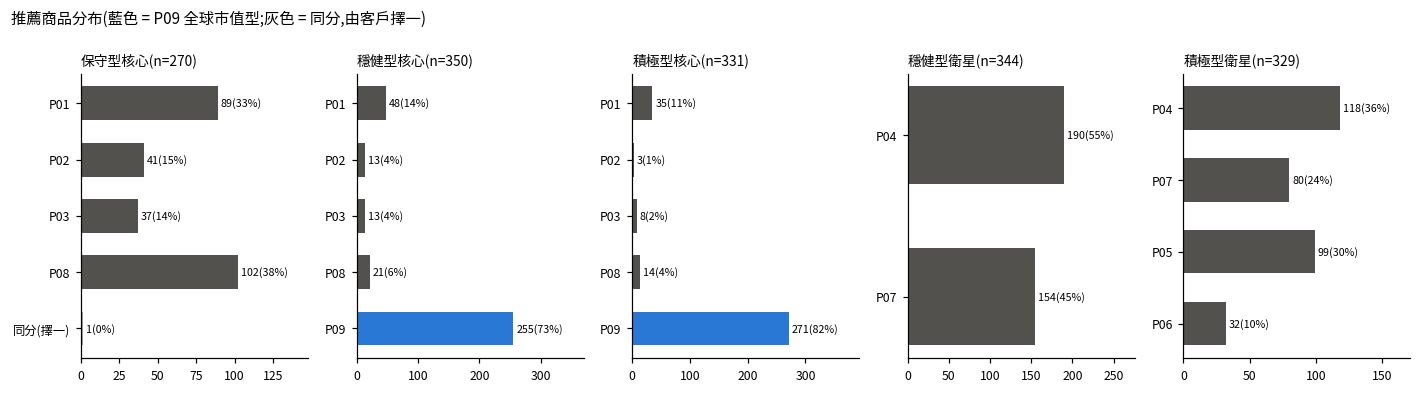

In [ ]:
groups = [(f"{k}核心", "core_label", k) for k in KYC_MAX_RISK] + [(f"{k}衛星", "sat_label", k) for k in ["穩健型", "積極型"]]
fig, axes = plt.subplots(1, len(groups), figsize=(13, 3.6), sharey=False)
for ax, (title, col, kyc) in zip(axes, groups):
    sub = df.loc[(df["kyc"] == kyc) & (df[col] != ""), col]
    counts = sub.value_counts()
    order = [p for p in CORE + SATELLITE if p in counts] + [p for p in counts.index if "擇一" in p]
    counts = counts.reindex(order)[::-1]
    counts.index = ["同分(擇一)" if "擇一" in p else p for p in counts.index]
    colors = [MAIN if p == "P09" else MUTED if "同分" in p else REF for p in counts.index]
    ax.barh(counts.index, counts.values, color=colors, height=0.6)
    for y, n in enumerate(counts.values):
        ax.text(n + max(counts) * 0.02, y, f"{n}({n / len(sub):.0%})", va="center", fontsize=7)
    ax.set_title(f"{title}(n={len(sub)})", loc="left", fontsize=9)
    ax.set_xlim(0, max(counts) * 1.45)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("推薦商品分布(藍色 = P09 全球市值型;灰色 = 同分,由客戶擇一)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# 方向檢查:主要消費類別 × 推薦商品
for title, col, kyc in groups:
    sub = df[(df["kyc"] == kyc) & (df[col] != "")]
    print(f"\n【{title}】")
    print(pd.crosstab(sub["top_cat"], sub[col]).reindex(CATS).fillna(0).astype(int).to_string())


【保守型核心】
core_label  P01  P01／P02／P03／P08（擇一）  P02  P03  P08
top_cat                                            
3C科技          6                    0    3   10    5
母嬰用品         59                    0   11    0    1
旅遊            0                    0    7   12    1
加油/交通         5                    0    4    4    7
居家生活          0                    0    1    1   24
外送平台          4                    0    2    4    8
餐飲            5                    0    5    1    9
精品/百貨         6                    0    1    3    7
超市/量販         1                    0    4    1   29
其他            3                    1    3    1   11

【穩健型核心】
core_label  P01  P02  P03  P08  P09
top_cat                            
3C科技          2    0    0    0   44
母嬰用品         42    9    0    1   33
旅遊            0    4   13    0    7
加油/交通         0    0    0    0   32
居家生活          1    0    0   10   24
外送平台          0    0    0    0   28
餐飲            0    0    0    0   17
精品/百貨         3    0    0    1   2

**我的解讀**：

合規率:100%（檢查 1,627 檔推薦，包括同分時列出的商品），配置合理性全部通過。且每檔產品都有被推薦過

符合權重表設計的部分：

母嬰 → P01（保守型核心）59 人，P02 11 人，和 Q7 的美債 56%、平衡型 35% 方向一致

旅遊 → P03（保守型核心）	12 人，P02 7 人，和 Q7 的高股息 52%、平衡型 31% 方向一致

旅遊 → P07（衛星）	穩健型 24／24、積極型 17／18

3C → P05（積極型衛星）	61／66

驗證第四節的假設：

保守型的 P08（102 人）中，53 人的主要消費類別是居家或超市（直接對應）、47 人的主要消費類別沒有核心商品（由次要消費決定）、2 人是母嬰和旅遊。驗證了第四節的假設：P08 主要靠民生支出和次要消費類別勝出。


不符合的部分：

穩健型母嬰／3C 客戶的衛星，因為 P04、P07 沒有母嬰、3C 的權重，只能改由次要消費類別決定，所以結果分散（母嬰 P04 47、P07 37；3C P04 22、P07 23）。積極型母嬰客戶的衛星也一樣分散。這是因為權重表沒有對應、且穩健型只有兩檔衛星可選擇所造成的

## 7. 輸出推薦結果

輸出 `outputs/recommendations.csv`（951 人），每位客戶一列：

| 欄位 | 說明 |
| --- | --- |
| `core_product`／`satellite_product` | 推薦商品代碼；同分時列出多檔，例如「P04／P07（擇一）」；沒有衛星時為空白 |
| `core_amount`／`satellite_amount` | 每月扣款金額（元） |
| `core_reason`／`satellite_reason` | 推薦理由 |
| `core_tie`／`satellite_tie` | 同分，由客戶選擇 |
| `satellite_shortfall` | 衛星金額不足 1,000 元，只配置核心 |

In [ ]:
out = df.rename(columns={"kyc": "kyc_risk_rating", "core_label": "core_product", "sat_label": "satellite_product"})
out["core_product_name"] = ["／".join(catalog.loc[p, "product_name"] for p in ps) for ps in df["core_list"]]
out["satellite_product_name"] = ["／".join(catalog.loc[p, "product_name"] for p in ps) for ps in df["sat_list"]]
out = out[["customer_id", "kyc_risk_rating", "sip",
           "core_product", "core_product_name", "core_amount", "core_reason",
           "satellite_product", "satellite_product_name", "satellite_amount", "satellite_reason",
           "core_tie", "satellite_tie", "satellite_shortfall"]]
os.makedirs("outputs", exist_ok=True)
out.to_csv("outputs/recommendations.csv", index=False)
print("已輸出:", len(out), "人")
out.head()

已輸出: 951 人


,customer_id,kyc_risk_rating,sip,core_product,core_product_name,core_amount,core_reason,satellite_product,satellite_product_name,satellite_amount,satellite_reason,core_tie,satellite_tie,satellite_shortfall
0,C108134,保守型,10000,P02,全球平衡配置基金,10000,你在旅遊的消費占比為 22%，推薦全球平衡配置基金,,,0,依你的風險屬性，建議全部配置在核心資產,False,False,False
1,C103236,積極型,10000,P09,全球市值型指數ETF,7000,你的消費分布在多個類別，沒有特別集中，推薦分散投資的全球市值型指數ETF,P07,全球旅遊消費主題基金,3000,你在旅遊的消費占比為 10%，推薦全球旅遊消費主題基金,False,False,False
2,C104381,保守型,10000,P02,全球平衡配置基金,10000,你在母嬰用品的消費占比為 34%，推薦全球平衡配置基金,,,0,依你的風險屬性，建議全部配置在核心資產,False,False,False
3,C100492,積極型,10000,P09,全球市值型指數ETF,7000,你的消費分布在多個類別，沒有特別集中，推薦分散投資的全球市值型指數ETF,P05,科技創新旗艦ETF,3000,你在3C科技的消費占比為 20%，推薦科技創新旗艦ETF,False,False,False
4,C101685,積極型,10000,P09,全球市值型指數ETF,7000,你的消費分布在多個類別，沒有特別集中，推薦分散投資的全球市值型指數ETF,P07,全球旅遊消費主題基金,3000,你在旅遊的消費占比為 25%，推薦全球旅遊消費主題基金,False,False,False


## 總結

| 項目 | 結果 |
| --- | --- |
| 推薦對象 | 期望價值排序的接觸名單 951 人（可推薦客戶的前 20%；保守型 270、穩健型 350、積極型 331） |
| 推薦結果 | 保守型核心以 P08 最多（102 人，37.8%）；穩健型、積極型核心以 P09 最多（255 人 72.9%、271 人 81.9%）；衛星：穩健型 P04 190、P07 154，積極型 P04 118、P05 99、P07 80、P06 32 |
| 同分與金額 | 同分 1 人（保守型，核心推薦全部 0 分，列出 P01／P02／P03／P08 讓客戶擇一），分數大於 0 的同分 0 人；衛星金額不足 8 人（穩健型 6、積極型 2），全部配置到核心，並建議月扣款提升至穩健型 5,000、積極型 4,000 元以上；有衛星的客戶中 315 人的金額不是千元整數，假設扣款以百元為單位 |
| 評估結果 | 合規率 100%（1,627 檔推薦，包括同分時列出的商品），配置合理性全部通過，每檔商品都有被推薦到；方向檢查：母嬰 → P01、旅遊 → P03（核心）／P07（衛星）、3C → P05，和權重表的設計一致；權重表沒有對應的類別（例如穩健型母嬰、3C 的衛星）推薦結果比較分散 |
| 限制 | ① P09 占大多數的核心推薦，核心推薦的個人化程度低，個人化主要靠衛星配置呈現 ② 部分類別沒有對應商品（例如穩健型母嬰／3C 的衛星），只能改由次要消費決定，所以結果分散 ③ 權重約半數依直覺（P06–P09 沒有資料可參考），有資料的部分也只是模擬的點擊行為 ④ 沒有購買紀錄，無法評估推薦是否準確，只能評估合規率、覆蓋率與配置合理性 ⑤ 嚴格遵守比例需要以百元為單位扣款，實務上各銀行的扣款級距不同 ⑥ 主題型推薦理由取對分數貢獻最大的類別，但有些客戶那一類的占比很低（例如「旅遊占比 10%」），文案的說服力弱 |
| 下一步 | KPI 量化試算（計畫書 4.6） |